# Hotel Booking Demand: decisions for revenue management

**Name: Seyha Seng — verify your submission name.**

AI assistance: ChatGPT helped draft code and explanations. Review the work and amend this disclosure to satisfy Hult’s AI policy.

### Management overview

**The pricing model is useful as a review reference; the cancellation model is not ready for automatic decisions.** The analysis addresses booking-time cancellation risk and daily rates among completed stays at two hotels. Later-period evaluation reduces average pricing error from 40.11 to 25.63 rate units. Cancellation detection is weak and sensitive to repeated records. We recommend a low-cost confirmation pilot and manager-led pricing review, not automatic overbooking or price changes. Historical associations identify where to investigate; they do not establish that an intervention increases revenue.

## 1. Understand and prepare the data

The dataset contains 119,390 bookings and 32 columns, with arrivals from July 2015 through August 2017. Missing values affect children (4), country (488), agent (16,340), and company (112,593). The latter three fields are not predictors, so their missingness does not justify deleting bookings. Missing children are imputed using training medians during modeling; guest screening does not assume missing children equal zero.

There are 31,994 repeated rows after first occurrence. They are retained because no booking identifier establishes whether identical records are duplicates or separate reservations. This preserves frequencies but can overweight copied records. A test-only sensitivity check examines the effect on evaluation, without resolving record identity or training duplication.

Zero-guest or zero-night bookings are outside the occupied-stay scope. Removing their overlapping union excludes 825 rows, leaving 118,565. Cancellation prevalence changes only slightly, from 37.04% to 37.26%. Pricing uses 74,388 completed stays with ADR between zero and 1,000. The upper limit is a screening assumption, not a verified business limit. Screening changes completed-stay mean ADR negligibly, from 101.0068 to 101.0082. The 1,000 zero-rate stays remain because complimentary accommodation may be legitimate.

Reservation status and its date are excluded from predictors. Assigned rooms, final amendments, waiting time, and later requests are also excluded because booking-time availability is uncertain. Status only defines the pricing population. Transaction-based ADR is excluded from cancellation predictors to avoid possible later information. Consequently, pricing findings concern completed stays, not every reservation or total hotel revenue.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, mean_absolute_error, r2_score

pd.set_option('display.max_columns', 12)
raw = pd.read_csv('hotels.csv')
print('Original shape:', raw.shape)
print(raw.dtypes)
print('Missing values:')
print(raw.isna().sum()[raw.isna().sum() > 0])
print('Repeated rows after first occurrence:', raw.duplicated().sum())
print(raw['adr'].describe())


Original shape: (119390, 32)
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent

In [2]:
data = raw.copy()
# Missing children remain unknown for guest screening, then are imputed for modeling.
data['total_guests'] = data['adults'] + data['children'] + data['babies']
data['total_nights'] = data['stays_in_week_nights'] + data['stays_in_weekend_nights']
data['arrival_date'] = pd.to_datetime(
    data['arrival_date_year'].astype(str) + '-' + data['arrival_date_month'] + '-' + data['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d')
print('Arrival coverage:', data['arrival_date'].min(), 'to', data['arrival_date'].max())
zero_guests = data['total_guests'].eq(0)
zero_nights = data['total_nights'].eq(0)
print('Zero guests:', zero_guests.sum(), 'Zero nights:', zero_nights.sum())
print('Excluded union:', (zero_guests | zero_nights).sum())
data = data.loc[~(zero_guests | zero_nights)].copy()
print('Remaining bookings:', len(data))
print('Negative ADR:', (data['adr'] < 0).sum(), 'ADR above 1000:', (data['adr'] > 1000).sum())
print('Cancellation rate raw / prepared:', raw['is_canceled'].mean(), data['is_canceled'].mean())
# Completed stays are a distinct pricing population; cancellation analysis keeps all outcomes.
pricing = data.loc[(data['reservation_status'] == 'Check-Out') & (data['adr'] >= 0) & (data['adr'] <= 1000)].copy()
print('Pricing rows:', len(pricing), 'Zero-rate stays retained:', pricing['adr'].eq(0).sum())
print('Completed ADR mean before / after rate screening:', data.loc[data['reservation_status']=='Check-Out','adr'].mean(), pricing['adr'].mean())


Arrival coverage: 2015-07-01 00:00:00 to 2017-08-31 00:00:00
Zero guests: 180 Zero nights: 715
Excluded union: 825
Remaining bookings: 118565
Negative ADR: 1 ADR above 1000: 1
Cancellation rate raw / prepared: 0.37041628277075134 0.3725888753004681
Pricing rows: 74388 Zero-rate stays retained: 1000
Completed ADR mean before / after rate screening: 101.00677196897391 101.00821557240414


## 2. Establish a baseline

The business should adopt a model only if it improves on a simple alternative. Training uses arrivals through December 2016; January–August 2017 evaluates performance. Arrival chronology is an imperfect proxy for booking chronology because long-lead reservations cross the boundary. Exploration uses training records only.

Cancellation training and evaluation contain 78,055 and 40,510 bookings. Always predicting no cancellation achieves 61.17% accuracy but catches no cancellations. The training cancellation probability is 36.44%. Accuracy alone therefore gives a misleading impression of operational usefulness.

For completed-stay pricing, the training mean ADR is 95.51. Using this same prediction for every later stay produces average absolute error of 40.11 rate units. This is the reference the pricing model must improve. Neither a baseline nor model error measures profitability.

In [3]:
cutoff = pd.Timestamp('2017-01-01')
train = data.loc[data['arrival_date'] < cutoff].copy()
test = data.loc[data['arrival_date'] >= cutoff].copy()
price_train = pricing.loc[pricing['arrival_date'] < cutoff].copy()
price_test = pricing.loc[pricing['arrival_date'] >= cutoff].copy()
majority = int(train['is_canceled'].mode().iloc[0])
base_cancel = np.repeat(majority, len(test))
base_adr = np.repeat(price_train['adr'].mean(), len(price_test))
print('Cancellation train/test:', len(train), len(test))
print('ADR train/test:', len(price_train), len(price_test))
print('Training cancellation probability:', train['is_canceled'].mean())
print('Test cancellation rate:', test['is_canceled'].mean())
print('Baseline cancellation accuracy:', accuracy_score(test['is_canceled'], base_cancel))
print('Baseline cancellation recall:', recall_score(test['is_canceled'], base_cancel, zero_division=0))
print('Training mean ADR:', price_train['adr'].mean())
print('Baseline ADR test MAE:', mean_absolute_error(price_test['adr'], base_adr))


Cancellation train/test: 78055 40510
ADR train/test: 49609 24779
Training cancellation probability: 0.36443533405931716
Test cancellation rate: 0.38829918538632435
Baseline cancellation accuracy: 0.6117008146136756
Baseline cancellation recall: 0.0
Training mean ADR: 95.50876474026892
Baseline ADR test MAE: 40.10755686606353


## 3. Visualize

### Cancellation: where management should investigate

Training-period City Hotel cancellation averages 41.53%, versus 26.58% at Resort Hotel. Long-lead bookings show a particularly clear gradient: cancellation rises from 10.15% within seven days to 59.95% beyond 180 days. Group bookings average 62.44%, versus 15.45% for Direct bookings. These findings support reviewing confirmation practices for long-lead and group reservations, rather than treating all reservations identically.

These are unadjusted comparisons, not proof that advance booking or channel causes cancellation. Contracts and customer mix may explain differences. Counts accompany rates: the Undefined segment has only two records, making its 100% cancellation unsuitable for policy.

### Daily rates: use comparable groups

The ADR distribution, hotel boxplots, and monthly hotel averages show why one overall rate is a weak reference. Monthly charts allow seasonal patterns to be examined separately by hotel; however, training begins in July 2015, so coverage is uneven. Management should compare similar hotel, season, room, and customer contexts before judging a rate. Room and segment are model inputs, but this notebook does not isolate their individual economic contributions or identify an optimal price.

Hotel cancellation rates and counts:
                   mean   size
hotel                        
City Hotel    0.415296  51503
Resort Hotel  0.265780  26552
Lead-time cancellation rates and counts:
                mean   size
lead_time                 
0–7        0.101477  13540
8–30       0.266704  12512
31–90      0.356858  20050
91–180     0.435406  15698
181+       0.599508  16255
Segment cancellation rates and counts:
                     mean   size
market_segment                 
Aviation        0.232000    125
Complementary   0.111984    509
Corporate       0.160870   3680
Direct          0.154462   7866
Groups          0.624407  13922
Offline TA/TO   0.347117  18403
Online TA       0.341898  33548
Undefined       1.000000      2


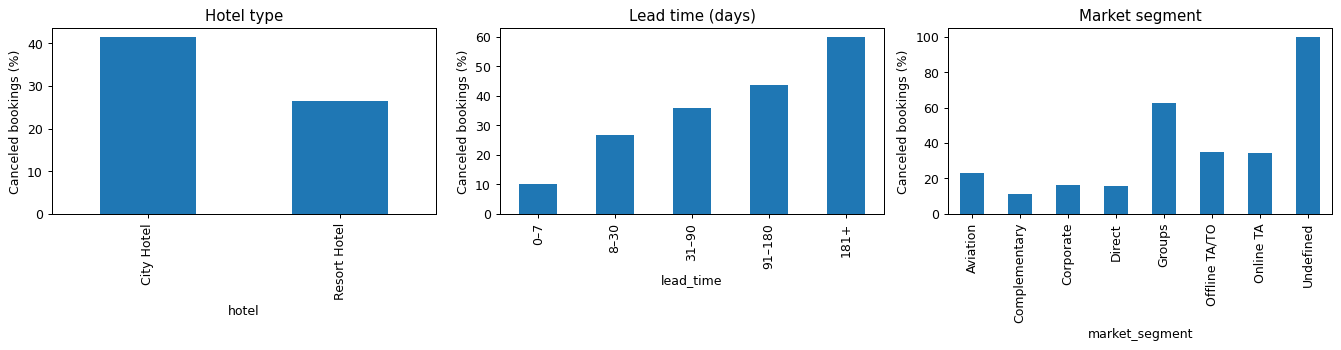

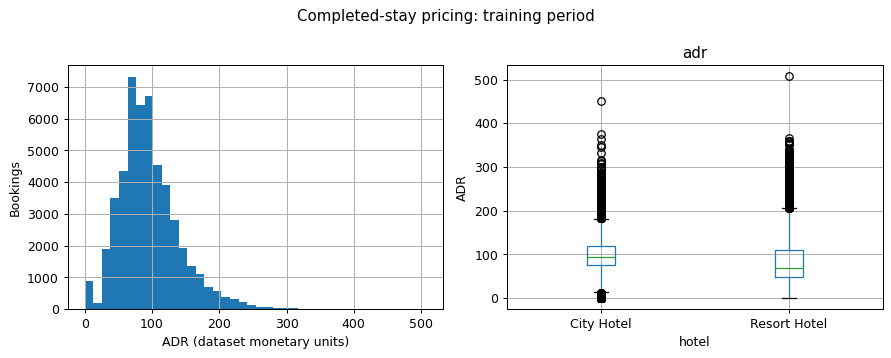

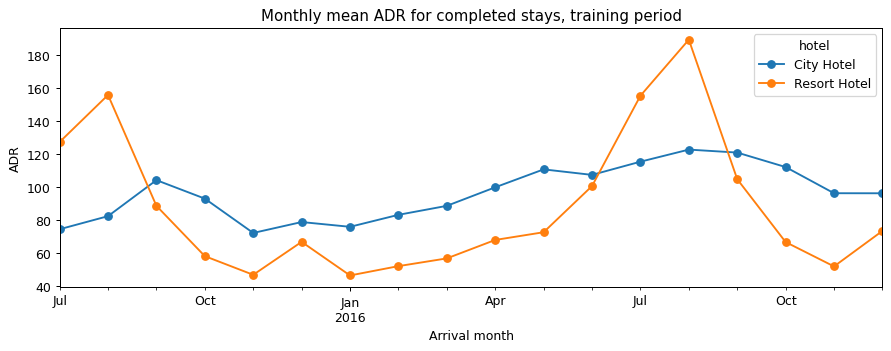

In [4]:
hotel_rates = train.groupby('hotel')['is_canceled'].agg(['mean','size'])
lead_groups = pd.cut(train['lead_time'], [-1,7,30,90,180,np.inf], labels=['0–7','8–30','31–90','91–180','181+'])
lead_rates = train.groupby(lead_groups, observed=True)['is_canceled'].agg(['mean','size'])
segment_rates = train.groupby('market_segment')['is_canceled'].agg(['mean','size'])
print('Hotel cancellation rates and counts:\n', hotel_rates)
print('Lead-time cancellation rates and counts:\n', lead_rates)
print('Segment cancellation rates and counts:\n', segment_rates)
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, table, title in zip(axes, [hotel_rates,lead_rates,segment_rates], ['Hotel type','Lead time (days)','Market segment']):
    (100*table['mean']).plot(kind='bar', ax=ax)
    ax.set_title(title); ax.set_ylabel('Canceled bookings (%)')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,4))
price_train['adr'].hist(bins=40, ax=axes[0])
axes[0].set_xlabel('ADR (dataset monetary units)'); axes[0].set_ylabel('Bookings')
price_train.boxplot(column='adr', by='hotel', ax=axes[1])
axes[1].set_ylabel('ADR'); fig.suptitle('Completed-stay pricing: training period')
plt.tight_layout(); plt.show()
monthly = price_train.groupby([pd.Grouper(key='arrival_date',freq='MS'),'hotel'])['adr'].mean().unstack()
monthly.plot(figsize=(10,4), marker='o')
plt.title('Monthly mean ADR for completed stays, training period')
plt.ylabel('ADR'); plt.xlabel('Arrival month'); plt.tight_layout(); plt.show()


## 4. Quantify uncertainty

Training completed-stay mean ADR is 100.93 for City Hotel, with approximate 95% t interval 100.52–101.35. Resort Hotel averages 87.13, with interval 86.36–87.89. The observed difference of 13.81 rate units is large enough to warrant separate hotel pricing references; it is not a justified instruction to raise resort rates by that amount.

Welch’s test gives p approximately 5.87 × 10^-208, strong evidence against equal means under its assumptions. The business decision depends on the size and context of the difference, not the tiny p-value. Room mix, season, and customers may explain the gap.

Intervals describe mean ADR, not individual booking prices or tomorrow’s achievable rate. Repeated customers, group reservations, possible copied rows, and seasonal dependence weaken independence assumptions and can make intervals too narrow. Uncertainty about transferring historical results to current operations is greater than these narrow statistical intervals suggest.

                   mean        std       sem  count  t_multiplier       lower  \
hotel                                                                           
City Hotel    100.93408  36.888274  0.212571  30114      1.960043  100.517431   
Resort Hotel   87.12826  54.616088  0.391164  19495      1.960086   86.361545   

                   upper  
hotel                     
City Hotel    101.350728  
Resort Hotel   87.894975  
City-minus-resort difference: 13.805819763295645
Welch test: TtestResult(statistic=np.float64(31.010944184759232), pvalue=np.float64(5.866488608163939e-208), df=np.float64(30960.045114841014))


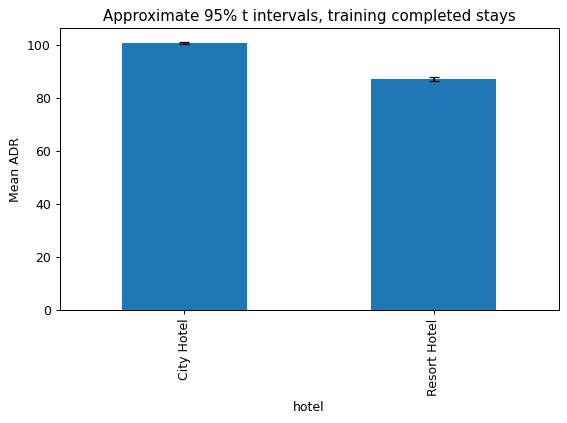

In [5]:
ci = price_train.groupby('hotel')['adr'].agg(['mean','std','sem','count'])
ci['t_multiplier'] = stats.t.ppf(0.975, ci['count']-1)
ci['lower'] = ci['mean'] - ci['t_multiplier']*ci['sem']
ci['upper'] = ci['mean'] + ci['t_multiplier']*ci['sem']
print(ci)
city = price_train.loc[price_train['hotel']=='City Hotel','adr']
resort = price_train.loc[price_train['hotel']=='Resort Hotel','adr']
welch = stats.ttest_ind(city, resort, equal_var=False)
print('City-minus-resort difference:', city.mean()-resort.mean())
print('Welch test:', welch)
ci['mean'].plot(kind='bar', yerr=ci['t_multiplier']*ci['sem'], capsize=4)
plt.ylabel('Mean ADR'); plt.title('Approximate 95% t intervals, training completed stays')
plt.tight_layout(); plt.show()


## 5. Model

### Cancellation: modest improvement, substantial missed risk

Logistic regression uses hotel, lead time, month, segment, reserved room, nights, party composition, repeat status, and prior cancellations. These have plausible booking-time roles, but immutable booking-time snapshots are unavailable. Training-only imputation, indicator encoding, and scaling support the classroom model. Chronological evaluation and prediction metrics are explained additions to the taught methods.

At a fixed 0.5 cutoff, accuracy is 65.05%, against the 61.17% baseline. Among flagged bookings, 59.51% cancel; only 31.28% of all cancellations are detected. The model finds 4,920 cancellations but misses 10,810 and incorrectly flags 3,347 noncancellations. Resort cancellation detection is 16.90%, versus City’s 36.27%. This may help prioritize inexpensive reminders, but cannot support booking rejection or an overbooking quantity.

Removing identical source rows from evaluation changes accuracy to 68.14%, barely above the 67.96% baseline, and detection to 21.20%. The model’s apparent advantage is therefore not robust to record weighting. The check leaves training unchanged and cannot establish which repeated records are valid.

### Pricing: useful reference, not an automatic pricing engine

Linear regression uses the same feature set among completed stays. Average absolute test error falls from 40.11 to 25.63 units, approximately a 36% improvement. Test R² is 0.529: explained variation relative to a mean reference, not percentage accuracy. Errors are larger at Resort Hotel (29.43) than City Hotel (23.43). The improvement persists when identical evaluation records are removed: 26.29 versus 42.30 units.

Holding included predictors fixed, an additional adult is associated with 12.51 higher ADR; another lead-time day with 0.040 lower ADR. These coefficients describe historical associations, not the return from changing party size or booking timing. Categorical inputs account for context, but their inclusion alone does not demonstrate importance.

Residuals show wider errors at higher predicted rates and a zero-rate band. Some expensive stays are underpredicted, and 94 predictions are negative. Excluding zero-rate test stays gives error 25.45, so they do not explain the overall limitation. Managers should review outputs, especially resort and high-rate cases. No demand response, occupancy optimization, or revenue-maximizing price is estimated.

In [6]:
# Features chosen before examining test outcomes; later-status fields are excluded.
numeric = ['lead_time','total_nights','adults','children','babies','is_repeated_guest','previous_cancellations']
categorical = ['hotel','arrival_date_month','market_segment','reserved_room_type']
features = numeric + categorical
# Training-only imputation and category columns. Missing and unseen categories have explicit labels.
def prepare_features(training, testing):
    a = training[features].copy()
    b = testing[features].copy()
    for col in numeric:
        value = a[col].median()
        a[col] = a[col].fillna(value)
        b[col] = b[col].fillna(value)
    for col in categorical:
        a[col] = a[col].fillna('Unknown')
        known = set(a[col])
        b[col] = b[col].fillna('Unknown')
        b.loc[~b[col].isin(known),col] = 'Unknown'
        # Include Unknown in the training schema, even if it has no training examples.
        categories = sorted(known | {'Unknown'})
        a[col] = pd.Categorical(a[col], categories=categories)
        b[col] = pd.Categorical(b[col], categories=categories)
    a = pd.get_dummies(a, columns=categorical, drop_first=True, dtype=float)
    b = pd.get_dummies(b, columns=categorical, drop_first=True, dtype=float)
    b = b.reindex(columns=a.columns, fill_value=0)
    return a, b

X_train, X_test = prepare_features(train, test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
cancel_model = LogisticRegression(max_iter=2000)
cancel_model.fit(X_train_scaled, train['is_canceled'])
probability = cancel_model.predict_proba(X_test_scaled)[:,1]
pred_cancel = (probability >= 0.5).astype(int)
cancel_results = pd.DataFrame({
    'baseline':[accuracy_score(test['is_canceled'],base_cancel), precision_score(test['is_canceled'],base_cancel,zero_division=0),recall_score(test['is_canceled'],base_cancel,zero_division=0)],
    'logistic':[accuracy_score(test['is_canceled'],pred_cancel),precision_score(test['is_canceled'],pred_cancel,zero_division=0),recall_score(test['is_canceled'],pred_cancel,zero_division=0)]},index=['accuracy','precision','recall'])
print(cancel_results)
print('Confusion matrix: rows actual 0/1, columns predicted 0/1')
print(confusion_matrix(test['is_canceled'],pred_cancel))
for hotel in test['hotel'].unique():
    mask = test['hotel'].eq(hotel)
    print(hotel,'accuracy',accuracy_score(test.loc[mask,'is_canceled'],pred_cancel[mask]),'recall',recall_score(test.loc[mask,'is_canceled'],pred_cancel[mask]))


           baseline  logistic
accuracy   0.611701  0.650531
precision  0.000000  0.595137
recall     0.000000  0.312778
Confusion matrix: rows actual 0/1, columns predicted 0/1
[[21433  3347]
 [10810  4920]]
Resort Hotel accuracy 0.7042854964160439 recall 0.1690106094251172
City Hotel accuracy 0.6247992407650752 recall 0.36267877023208017


            baseline     linear
MAE        40.107557  25.625966
R_squared  -0.098701   0.528901
Selected ADR coefficients: lead_time                 -0.039833
total_nights              -0.473790
adults                    12.508978
children                  14.750166
babies                     5.586639
is_repeated_guest         -5.401214
previous_cancellations    -0.380679
dtype: float64
Resort Hotel ADR MAE 29.429889186123912
City Hotel ADR MAE 23.433489734949514
Negative ADR predictions: 94
Positive-ADR test MAE: 25.448364629998487


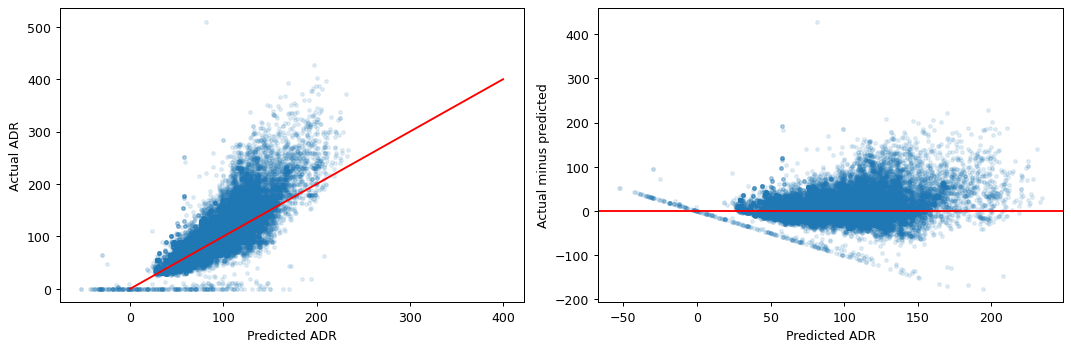

In [7]:
Xp_train, Xp_test = prepare_features(price_train, price_test)
adr_model = LinearRegression()
adr_model.fit(Xp_train, price_train['adr'])
pred_adr = adr_model.predict(Xp_test)
price_results = pd.DataFrame({
    'baseline':[mean_absolute_error(price_test['adr'],base_adr),r2_score(price_test['adr'],base_adr)],
    'linear':[mean_absolute_error(price_test['adr'],pred_adr),r2_score(price_test['adr'],pred_adr)]},index=['MAE','R_squared'])
print(price_results)
coef = pd.Series(adr_model.coef_,index=Xp_train.columns)
print('Selected ADR coefficients:',coef[numeric])
for hotel in price_test['hotel'].unique():
    mask = price_test['hotel'].eq(hotel)
    print(hotel,'ADR MAE',mean_absolute_error(price_test.loc[mask,'adr'],pred_adr[mask]))
print('Negative ADR predictions:',(pred_adr<0).sum())
residuals = price_test['adr'].to_numpy()-pred_adr
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(pred_adr,price_test['adr'],alpha=.12,s=8)
axes[0].plot([0,400],[0,400],color='red')
axes[0].set_xlabel('Predicted ADR'); axes[0].set_ylabel('Actual ADR')
axes[1].scatter(pred_adr,residuals,alpha=.12,s=8); axes[1].axhline(0,color='red')
axes[1].set_xlabel('Predicted ADR'); axes[1].set_ylabel('Actual minus predicted')
plt.tight_layout(); plt.show()
# Sensitivity check: same fitted model, evaluation excludes zero ADR.
positive = price_test['adr'].gt(0)
print('Positive-ADR test MAE:',mean_absolute_error(price_test.loc[positive,'adr'],pred_adr[positive]))


In [8]:
# Identical source records may overweight evaluations: test-only sensitivity.
keep_cancel = ~raw.loc[test.index].duplicated()
keep_price = ~raw.loc[price_test.index].duplicated()
print('Unique-source-row cancellation test size:', keep_cancel.sum())
print('Deduplicated test baseline accuracy:', accuracy_score(test.loc[keep_cancel,'is_canceled'], base_cancel[keep_cancel]))
print('Deduplicated test logistic accuracy:', accuracy_score(test.loc[keep_cancel,'is_canceled'], pred_cancel[keep_cancel]))
print('Deduplicated test logistic recall:', recall_score(test.loc[keep_cancel,'is_canceled'], pred_cancel[keep_cancel]))
print('Unique-source-row ADR test size:', keep_price.sum())
print('Deduplicated test baseline ADR MAE:', mean_absolute_error(price_test.loc[keep_price,'adr'], base_adr[keep_price]))
print('Deduplicated test model ADR MAE:', mean_absolute_error(price_test.loc[keep_price,'adr'], pred_adr[keep_price]))


Unique-source-row cancellation test size: 31530
Deduplicated test baseline accuracy: 0.6796067237551539
Deduplicated test logistic accuracy: 0.6814145258483983
Deduplicated test logistic recall: 0.21203722035240546
Unique-source-row ADR test size: 21427
Deduplicated test baseline ADR MAE: 42.29682898392088
Deduplicated test model ADR MAE: 26.28680959617255


## 6. Recommendation

**Start with controlled operational pilots, not full deployment.**

| Action | Owner | Measure of success |
| --- | --- | --- |
| Pilot confirmation reminders for selected long-lead or group bookings | Reservations team | Cancellation and completed-stay rates versus usual practice; staff time and complaints |
| Use predicted ADR to flag bookings for contextual review | Revenue manager | Useful flags, review time, occupancy, achieved ADR, and revenue per available room |
| Validate on recent booking-time records before expansion | Analytics team | Detection, false alarms, pricing errors, and stability by hotel |

Where feasible, randomly assign eligible bookings to the reminder pilot or usual practice. Do not treat sending reminders as proven to prevent cancellations. Establish acceptable costs and outcomes before assessing results. Avoid automatic rejection and model-based overbooking because missed cancellations and false flags are substantial.

Pricing flags should prompt review of season, room, segment, and market conditions, not automatic increases. A pricing change requires its own controlled evaluation: a higher achieved rate can still reduce occupancy or revenue. The current model benchmarks historical completed stays and cannot determine customers’ willingness to pay.

Confidence is strongest in observed historical comparisons and measured evaluation results. Data cover only two hotels and end in 2017; current demand, repeated records, completed-stay selection, and uncertain booking-time availability limit applicability. Use recent data and prospective evaluation before claiming business benefits. The strongest deliverable is a transparent decision process, not a claim that either model guarantees better revenue.

## Submission check

Restart the Colab runtime and run all cells in order with `hotels.csv` in the working directory. Verify your name and AI disclosure, then submit this notebook and the CSV. Code comments do not count toward the narrative word limit.
